<a href="https://colab.research.google.com/github/kjyoshnapriya/fake-news-detection/blob/main/Fake_News_Detection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Fake News Detection using Machine Learning
Subject: Machine Learning | Course: B.Tech CSE (AI & DS)

Pipeline: Dataset → Text cleaning → TF-IDF → ML models → Evaluation → Backend (Flask API) → Frontend (Gradio web app)

Before you start: download the Kaggle dataset "Fake and Real News Dataset" (Fake.csv and True.csv) by Clément Bisaillon. You will upload both files in Step 2. (If you skip the upload, a tiny demo dataset is used so the notebook still runs, but accuracy will not be meaningful.)

##Introduction

Fake News Detection is a Machine Learning project used to identify whether a news article is Fake or Real. Nowadays, fake news spreads quickly through social media platforms. This project helps users identify misleading information by analysing news text.

##Objective

The main objective is to classify news articles into two categories: Fake News and Real News using Machine Learning algorithms.

##Methodology

Collect the Fake and Real News dataset.

Clean and preprocess the text.

Convert text into numerical features using TF-IDF.

Train different Machine Learning algorithms.

Compare model performance.

Predict whether the given news is Fake or Real.

##Technologies Used

Python

Google Colab

Pandas and NumPy

Scikit-learn

Matplotlib and Seaborn

Flask and Gradio

##Step 1: Install and import libraries

In [1]:
# Installing the libraries required for our project

!pip install -q gradio flask scikit-learn joblib


In [2]:
# Importing the libraries needed for fake news detection

import re
import io
import time
import threading
import joblib
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning libraries
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import PassiveAggressiveClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

##Step 2: Load the dataset
Label convention used everywhere: 0 = Fake, 1 = Real

In [3]:
# Loading the fake and real news datasets

import io
import os
from google.colab import files
import pandas as pd

print("/content/Fake.csv and /content/True.csv")

uploaded_files = files.upload()

# Helper function to find files starting with Fake/True either in uploaded files or in the current directory
def find_file_path_or_data(prefix):
    # 1. Check in actively uploaded files
    uploaded_key = next((k for k in uploaded_files.keys() if k.lower().startswith(prefix.lower())), None)
    if uploaded_key:
        return io.BytesIO(uploaded_files[uploaded_key])

    # 2. Check in current directory (/content/)
    local_files = os.listdir('.')
    matching_files = [f for f in local_files if f.lower().startswith(prefix.lower()) and f.endswith('.csv')]
    if matching_files:
        # Sort to get the most relevant one if duplicates exist (e.g., 'True.csv' before 'True (1).csv')
        matching_files.sort(key=len)
        print(f"Found existing local file for {prefix}: {matching_files[0]}")
        return matching_files[0]

    return None

fake_source = find_file_path_or_data("Fake")
true_source = find_file_path_or_data("True")

if not fake_source or not true_source:
    raise FileNotFoundError(
        "Missing required datasets. Please make sure to upload or have both Fake and True CSV files in your workspace."
    )

# Read the CSV files
fake_news = pd.read_csv(fake_source)
real_news = pd.read_csv(true_source)

# Check whether the required columns are available
required_columns = {"title", "text"}

for column in required_columns:
    if column not in fake_news.columns or column not in real_news.columns:
        raise ValueError(f"Required column '{column}' is missing.")

# Assign labels
# 0 represents Fake News
# 1 represents Real News

fake_news["label"] = 0
real_news["label"] = 1

# Combine both datasets
df = pd.concat(
    [fake_news, real_news],
    ignore_index=True
)

# Combine title and article text
df["text_all"] = (
    df["title"].fillna("").astype(str)
    + " "
    + df["text"].fillna("").astype(str)
)

# Remove rows without useful text
df = df[df["text_all"].str.strip() != ""]

# We are using the actual uploaded datasets
USING_DEMO = False

print("\nDatasets loaded successfully!")
print("Fake news articles:", len(fake_news))
print("Real news articles:", len(real_news))
print("Total articles:", len(df))

# Display a few sample records
df[["title", "label"]].head()

/content/Fake.csv and /content/True.csv


Saving True.csv to True (1).csv
Saving Fake.csv to Fake (1).csv

Datasets loaded successfully!
Fake news articles: 23481
Real news articles: 21417
Total articles: 44898


,title,label
0,Donald Trump Sends Out Embarrassing New Year’...,0
1,Drunk Bragging Trump Staffer Started Russian ...,0
2,Sheriff David Clarke Becomes An Internet Joke...,0
3,Trump Is So Obsessed He Even Has Obama’s Name...,0
4,Pope Francis Just Called Out Donald Trump Dur...,0


##Step 3: Clean the text
Real news in this dataset often starts with a location and "(Reuters)". A model can cheat by learning that word, so we remove such patterns to avoid data leakage.

In [4]:
# Cleaning news articles before training the model

import re

def clean_text(text):

    # Convert text into lowercase
    text = str(text).lower()

    # Remove Reuters location information
    text = re.sub(
        r"^.{0,60}\(reuters\)\s*-?\s*",
        " ",
        text
    )

    # Remove the word Reuters
    text = re.sub(r"reuters", " ", text)

    # Remove website links
    text = re.sub(
        r"https?://\S+|www\.\S+",
        " ",
        text
    )

    # Keep only English letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Remove duplicate news articles
df = df.drop_duplicates(
    subset="text_all"
).reset_index(drop=True)

# Apply cleaning to all news articles
df["clean"] = df["text_all"].apply(clean_text)

# Remove empty articles
df = df[df["clean"].str.len() > 0].reset_index(drop=True)

print("Text cleaning completed!")
print("Total articles after cleaning:", len(df))

# Display cleaned news samples
df[["clean", "label"]].head()

Text cleaning completed!
Total articles after cleaning: 39100


,clean,label
0,donald trump sends out embarrassing new year s...,0
1,drunk bragging trump staffer started russian c...,0
2,sheriff david clarke becomes an internet joke ...,0
3,trump is so obsessed he even has obama s name ...,0
4,pope francis just called out donald trump duri...,0


##Step 4: Exploratory data analysis

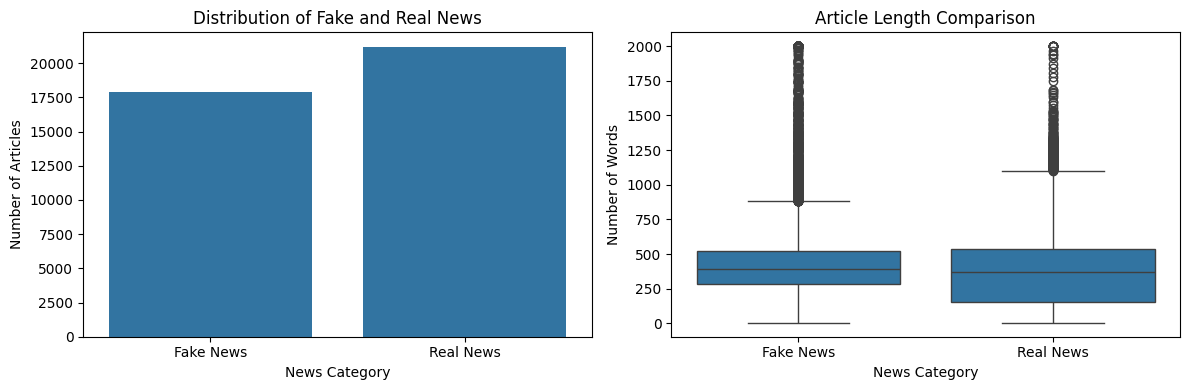

In [5]:
# Explore the dataset using visualizations

plt.figure(figsize=(12, 4))

# Compare Fake and Real news counts
plt.subplot(1, 2, 1)

sns.countplot(
    x=df["label"].map({
        0: "Fake News",
        1: "Real News"
    })
)

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

# Calculate article length
df["word_count"] = df["clean"].str.split().str.len()

plt.subplot(1, 2, 2)

sns.boxplot(
    x=df["label"].map({
        0: "Fake News",
        1: "Real News"
    }),
    y=df["word_count"].clip(upper=2000)
)

plt.title("Article Length Comparison")
plt.xlabel("News Category")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()

##Step 5: Train / test split

In [8]:
X = df["clean"]
y = df["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y if not USING_DEMO else None
)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 31280  Test: 7820


##Step 6: Build and compare ML models
Each model is a scikit-learn Pipeline (TF-IDF → classifier), so the same object can be saved and used by the backend.

In [9]:
# Create a function to build the ML pipeline

def create_model(classifier):

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            max_df=0.7,
            min_df=5,
            ngram_range=(1, 2),
            max_features=100000,
            sublinear_tf=True
        )),

        ("classifier", classifier)
    ])

    return model


# Select the algorithms for comparison

models = {
    "Logistic Regression": create_model(
        LogisticRegression(max_iter=1000, C=5)
    ),

    "Naive Bayes": create_model(
        MultinomialNB()
    ),

    "Linear SVM": create_model(
        LinearSVC()
    ),

    "Passive Aggressive": create_model(
        PassiveAggressiveClassifier(
            max_iter=50,
            random_state=42
        )
    )
}


# Train and evaluate each model

results = []

for name, model in models.items():

    print("Training:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    f1 = f1_score(
        y_test,
        predictions,
        average="macro"
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "F1 Score": f1
    })


# Display model comparison

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

print("Machine Learning Model Comparison")

display(results_df)

Training: Logistic Regression
Training: Naive Bayes
Training: Linear SVM
Training: Passive Aggressive
Machine Learning Model Comparison


,Model,Accuracy,F1 Score
3,Passive Aggressive,0.993223,0.993171
2,Linear SVM,0.992455,0.992397
0,Logistic Regression,0.987980,0.987881
1,Naive Bayes,0.954092,0.953776


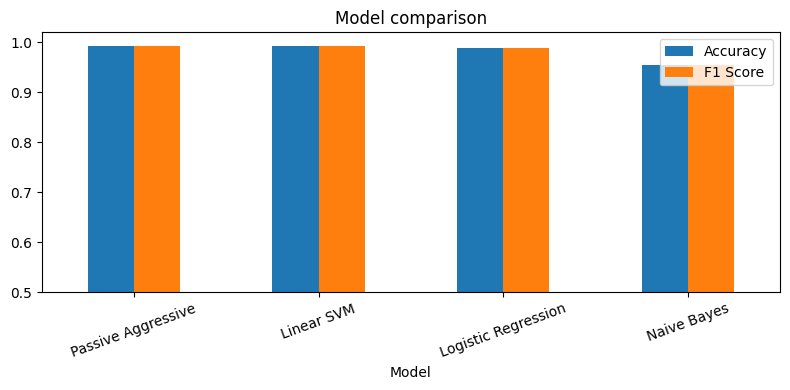

In [10]:
results_df.set_index("Model")[["Accuracy", "F1 Score"]].plot(kind="bar", figsize=(8, 4), ylim=(0.5, 1.02))
plt.title("Model comparison"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

##Step 7: Final model evaluation
We deploy Logistic Regression because it gives probabilities (a confidence score) and is easy to explain.

Final Model Accuracy: 98.8 %

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.99      0.98      0.99      3581
   Real News       0.98      0.99      0.99      4239

    accuracy                           0.99      7820
   macro avg       0.99      0.99      0.99      7820
weighted avg       0.99      0.99      0.99      7820



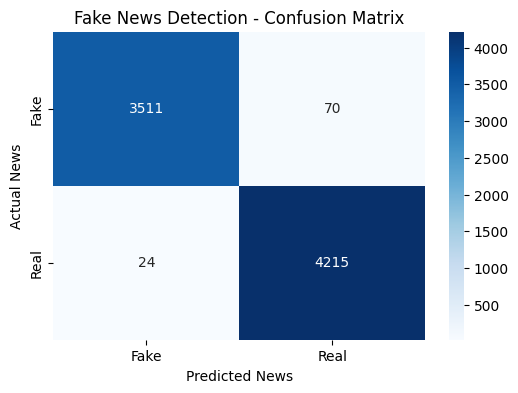

In [11]:
# Select Logistic Regression as our final model

final_model = models["Logistic Regression"]

# Generate predictions on test data
predictions = final_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, predictions)

print("Final Model Accuracy:", round(accuracy * 100, 2), "%")

# Display precision, recall and F1-score
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        predictions,
        target_names=["Fake News", "Real News"]
    )
)

# Create confusion matrix
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted News")
plt.ylabel("Actual News")
plt.title("Fake News Detection - Confusion Matrix")

plt.show()

In [12]:
# Display the words that influence the model's predictions

tfidf = final_model.named_steps["tfidf"]
classifier = final_model.named_steps["classifier"]

words = np.array(tfidf.get_feature_names_out())
weights = classifier.coef_[0]

sorted_indices = np.argsort(weights)

print("Words associated with Fake News:")
print(", ".join(words[sorted_indices[:15]]))

print("\nWords associated with Real News:")
print(", ".join(words[sorted_indices[-15:][::-1]]))

Words associated with Fake News:
video, image, read, featured image, featured, just, gop, obama, president trump, watch, america, getty, getty images, breaking, hillary

Words associated with Real News:
washington, president donald, wednesday, tuesday, thursday, republican, friday, nov, monday, said statement, minister, spokesman, washington president, trump said, president barack


#Most important words (model explanation)

In [13]:
tfidf = final_model.named_steps["tfidf"]
classifier = final_model.named_steps["classifier"]
names = np.array(tfidf.get_feature_names_out())
coef = classifier.coef_[0]
order = np.argsort(coef)

print("Words pushing towards FAKE :", ", ".join(names[order[:15]]))
print("Words pushing towards REAL :", ", ".join(names[order[-15:]][::-1]))

Words pushing towards FAKE : video, image, read, featured image, featured, just, gop, obama, president trump, watch, america, getty, getty images, breaking, hillary
Words pushing towards REAL : washington, president donald, wednesday, tuesday, thursday, republican, friday, nov, monday, said statement, minister, spokesman, washington president, trump said, president barack


##Step 8: Save the model

In [14]:
joblib.dump(final_model, "fake_news_model.joblib")
print("Saved fake_news_model.joblib")

Saved fake_news_model.joblib


In [16]:
# Save the trained model for future predictions

joblib.dump(final_model, "fake_news_model.joblib")

print("Model saved successfully!")

Model saved successfully!


##Step 9: BACKEND — Flask REST API
The backend loads the saved model and exposes a /predict endpoint that accepts JSON and returns the prediction and confidence. It runs in a background thread inside Colab.

In [17]:
# Import Flask
from flask import Flask, request, jsonify

# Load our trained Machine Learning model
model = joblib.load("fake_news_model.joblib")

# Create Flask application
app = Flask(__name__)


# Check whether the backend is running
@app.route("/health", methods=["GET"])
def health():

    return jsonify({
        "status": "success",
        "message": "Fake News Detection API is running"
    })


# Predict whether the given news is Fake or Real
@app.route("/predict", methods=["POST"])
def predict():

    data = request.get_json(silent=True) or {}

    news_text = data.get("text", "")

    # Check user input
    if not isinstance(news_text, str) or len(news_text.split()) < 5:

        return jsonify({
            "error": "Please enter a news article with at least 5 words."
        }), 400

    # Clean the submitted news
    cleaned_news = clean_text(news_text)

    if not cleaned_news:
        return jsonify({
            "error": "Please enter valid news text."
        }), 400

    # Generate prediction
    probabilities = model.predict_proba([cleaned_news])[0]

    fake_probability = float(probabilities[0])
    real_probability = float(probabilities[1])

    # Select the predicted category
    if fake_probability > real_probability:
        prediction = "Fake"
    else:
        prediction = "Real"

    # Return the prediction to the frontend
    return jsonify({
        "prediction": prediction,
        "prob_fake": fake_probability,
        "prob_real": real_probability
    })


# Start the Flask server in the background
def run_flask():

    app.run(
        host="127.0.0.1",
        port=5000,
        debug=False,
        use_reloader=False
    )


flask_thread = threading.Thread(
    target=run_flask,
    daemon=True
)

flask_thread.start()

# Give the server time to start
time.sleep(3)

# Test the backend
response = requests.get(
    "http://127.0.0.1:5000/health"
)

print("Backend response:", response.json())

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on http://127.0.0.1:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [21/Nov/2026 17:05:24] "GET /health HTTP/1.1" 200 -


Backend response: {'message': 'Fake News Detection API is running', 'status': 'success'}


In [18]:
# Test our prediction API

sample_news = """
The government announced a new development project
for improving public transportation across the country.
"""

response = requests.post(
    "http://127.0.0.1:5000/predict",
    json={"text": sample_news}
)

print("API Result:")
print(response.json())

INFO:werkzeug:127.0.0.1 - - [21/Nov/2026 17:05:35] "POST /predict HTTP/1.1" 200 -


API Result:
{'prediction': 'Real', 'prob_fake': 0.4959683335564147, 'prob_real': 0.5040316664435853}


##Step 10: FRONTEND — Gradio web app
The frontend is a web page where the user pastes a news article. It sends the text to the Flask backend and shows the result. A public link (*.gradio.live) is printed that you can open on any device or share for the demo.

In [19]:
# Import Gradio
import gradio as gr

# Flask backend address
API_URL = "http://127.0.0.1:5000/predict"


# Function to communicate with Flask
def check_news(news_text):

    if not news_text or len(news_text.split()) < 5:
        return "Please enter at least 5 words.", None

    try:

        # Send news text to the backend
        response = requests.post(
            API_URL,
            json={"text": news_text},
            timeout=30
        )

        result = response.json()

        # Display backend validation errors
        if response.status_code != 200:
            return result.get("error", "Prediction failed."), None

        prediction = result["prediction"]

        fake_score = result["prob_fake"] * 100
        real_score = result["prob_real"] * 100

        # Prepare the result for display
        output = f"""
        ## Prediction: {prediction.upper()}

        **Fake News Score:** {fake_score:.2f}%

        **Real News Score:** {real_score:.2f}%

        ---
        *This result is generated by a Machine Learning model.
        It is not a guarantee that the news is factually true.*
        """

        scores = {
            "Fake News": result["prob_fake"],
            "Real News": result["prob_real"]
        }

        return output, scores

    except requests.exceptions.RequestException:
        return "Unable to connect to the Flask backend. Please check the server.", None

    except Exception as error:
        return f"An error occurred: {error}", None


# Example news articles
examples = [
    [
        "Scientists have discovered a miracle medicine that can cure every disease overnight."
    ],
    [
        "The finance ministry announced the latest economic growth figures on Tuesday."
    ]
]


# Build the Gradio interface
with gr.Blocks(theme=gr.themes.Soft()) as demo:

    gr.Markdown(
        """
        # Fake News Detection System

        ### Machine Learning Based News Classification

        Enter a news headline or article below to check its predicted category.
        """
    )

    news_input = gr.Textbox(
        lines=8,
        label="Enter News Article",
        placeholder="Paste your news headline or article here..."
    )

    check_button = gr.Button(
        "Check News",
        variant="primary"
    )

    result_output = gr.Markdown(
        label="Prediction Result"
    )

    score_output = gr.Label(
        num_top_classes=2,
        label="Prediction Scores"
    )

    gr.Examples(
        examples=examples,
        inputs=news_input
    )

    check_button.click(
        fn=check_news,
        inputs=news_input,
        outputs=[result_output, score_output]
    )


# Launch the application
demo.launch(
    share=True,
    debug=False
)

/tmp/ipykernel_1040/3891871003.py:73: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9c5f5682d16ca5d668.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


##PROJECT CONCLUSION

The Fake News Detection System is developed using Machine Learning techniques to classify news articles into Fake News and Real News categories.

The project uses the Fake and Real News dataset. Text preprocessing is performed to remove unwanted characters, links and duplicate articles.

TF-IDF is used to convert textual information into numerical features that can be understood by Machine Learning algorithms.

Four algorithms are implemented and compared:

Logistic Regression
Naive Bayes
Linear SVM
Passive Aggressive Classifier
The trained model is connected to a Flask backend, which receives news articles and returns predictions.

A Gradio frontend provides a simple interface where users can enter news articles and view the results.

#LIMITATIONS

1. The model may not correctly classify every news article.
2. It mainly learns patterns from the training dataset.
3. News from different countries or languages may produce incorrect predictions.
4. A high accuracy score does not guarantee factual truth.
5. The model may be affected by bias in the dataset.


#FUTURE ENHANCEMENTS

1. Implement advanced models such as BERT.
2. Add support for Hindi and regional languages.
3. Integrate reliable fact-checking services.
4. Improve the frontend design.
5. Use more recent and diverse news datasets.